<a href="https://colab.research.google.com/github/Indhirayc/PBL_Kelompok1_LeafItToMe/blob/feature%2Fml-training/LeafItToMe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import userdata

token = userdata.get('GITHUB_TOKEN')

if token:
    print("Token berhasil dibaca")
else:
    print("Token belum ditemukan")

SecretNotFoundError: Secret GITHUB_TOKEN does not exist.

In [ ]:
from google.colab import userdata
import subprocess
import base64

token = userdata.get('GITHUB_TOKEN')

if not token:
    raise ValueError(
        "GITHUB_TOKEN tidak ditemukan. "
        "Periksa nama secret dan aktifkan Akses notebook."
    )

auth = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

repo_url = "https://github.com/Indhirayc/PBL_Kelompok1_LeafItToMe.git"

result = subprocess.run(
    [
        "git",
        "-c",
        f"http.extraheader=AUTHORIZATION: basic {auth}",
        "clone",
        repo_url
    ],
    text=True,
    capture_output=True
)

print(result.stdout)
print(result.stderr)

if result.returncode == 0:
    print("Repository berhasil di-clone!")
else:
    print("Clone gagal. Periksa izin token.")

SecretNotFoundError: Secret GITHUB_TOKEN does not exist.

In [ ]:
%cd /content/PBL_Kelompok1_LeafItToMe

/content/PBL_Kelompok1_LeafItToMe


In [ ]:
!git status
!ls

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
README.md


In [ ]:
!git checkout -b feature/ml-training

Switched to a new branch 'feature/ml-training'


In [ ]:
!git branch

* feature/ml-training
  main


In [ ]:
from pathlib import Path

folders = [
    "machine_learning/notebooks",
    "machine_learning/models",
    "machine_learning/results",
    "dataset"
]

for folder in folders:
    Path(folder).mkdir(parents=True, exist_ok=True)

print("Struktur folder berhasil dibuat.")

Struktur folder berhasil dibuat.


In [ ]:
Path("machine_learning/README.md").write_text(
    """# Machine Learning LeafItToMe

Folder ini berisi notebook, model, dan hasil evaluasi machine learning.

## Struktur

- `notebooks/` — notebook Google Colab
- `models/` — model hasil training
- `results/` — grafik dan hasil evaluasi
""",
    encoding="utf-8"
)

Path("dataset/README.md").write_text(
    """# Dataset LeafItToMe

Dataset disimpan di Google Drive bersama dan tidak diunggah langsung ke GitHub.

Setiap anggota harus memperoleh akses ke folder dataset melalui akun Google
masing-masing.
""",
    encoding="utf-8"
)

Path("machine_learning/notebooks/.gitkeep").touch()
Path("machine_learning/models/.gitkeep").touch()
Path("machine_learning/results/.gitkeep").touch()

print("File README dan .gitkeep berhasil dibuat.")

File README dan .gitkeep berhasil dibuat.


In [ ]:
!find . -maxdepth 3 -type f

./.gitignore
./dataset/README.md
./README.md
./.git/logs/HEAD
./.git/info/exclude
./.git/index
./.git/packed-refs
./.git/description
./.git/HEAD
./.git/config
./.git/hooks/pre-push.sample
./.git/hooks/update.sample
./.git/hooks/post-update.sample
./.git/hooks/push-to-checkout.sample
./.git/hooks/prepare-commit-msg.sample
./.git/hooks/fsmonitor-watchman.sample
./.git/hooks/pre-merge-commit.sample
./.git/hooks/pre-applypatch.sample
./.git/hooks/sendemail-validate.sample
./.git/hooks/pre-receive.sample
./.git/hooks/pre-commit.sample
./.git/hooks/commit-msg.sample
./.git/hooks/pre-rebase.sample
./.git/hooks/applypatch-msg.sample
./machine_learning/results/.gitkeep
./machine_learning/models/.gitkeep
./machine_learning/README.md
./machine_learning/notebooks/.gitkeep


In [ ]:
!git config user.name "Indhira Yuantika Christy"
!git config user.email "indhirayuantikac1176@gmail.com"

In [ ]:
!git add .
!git commit -m "ml: add machine learning project structure"

[feature/ml-training 69bf982] ml: add machine learning project structure
 5 files changed, 15 insertions(+)
 create mode 100644 dataset/README.md
 create mode 100644 machine_learning/README.md
 create mode 100644 machine_learning/models/.gitkeep
 create mode 100644 machine_learning/notebooks/.gitkeep
 create mode 100644 machine_learning/results/.gitkeep


In [ ]:
result_push = subprocess.run(
    [
        "git",
        "-c",
        f"http.extraheader=AUTHORIZATION: basic {auth}",
        "push",
        "-u",
        "origin",
        "feature/ml-training"
    ],
    text=True,
    capture_output=True
)

print(result_push.stdout)
print(result_push.stderr)

branch 'feature/ml-training' set up to track 'origin/feature/ml-training'.

remote: 
remote: Create a pull request for 'feature/ml-training' on GitHub by visiting:        
remote:      https://github.com/Indhirayc/PBL_Kelompok1_LeafItToMe/pull/new/feature/ml-training        
remote: 
To https://github.com/Indhirayc/PBL_Kelompok1_LeafItToMe.git
 * [new branch]      feature/ml-training -> feature/ml-training



In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

DATASET_DIR = Path('/content/drive/MyDrive/dataset')

if DATASET_DIR.exists():
    print('Dataset berhasil ditemukan.')
    print('Lokasi dataset:', DATASET_DIR)
else:
    raise FileNotFoundError(
        'Folder "data set" tidak ditemukan. '
        'Pastikan folder sudah dibagikan dan shortcut sudah ditambahkan ke My Drive.'
    )

Dataset berhasil ditemukan.
Lokasi dataset: /content/drive/MyDrive/dataset


Total Kelas  : 5
Total Gambar : 13781

Distribusi per kelas:
 - Bacterial_spot: 2827 gambar
 - Late_blight: 3113 gambar
 - Leaf_Mold: 2754 gambar
 - Tomato_Yellow_Leaf_Curl_Virus: 2036 gambar
 - healthy: 3051 gambar


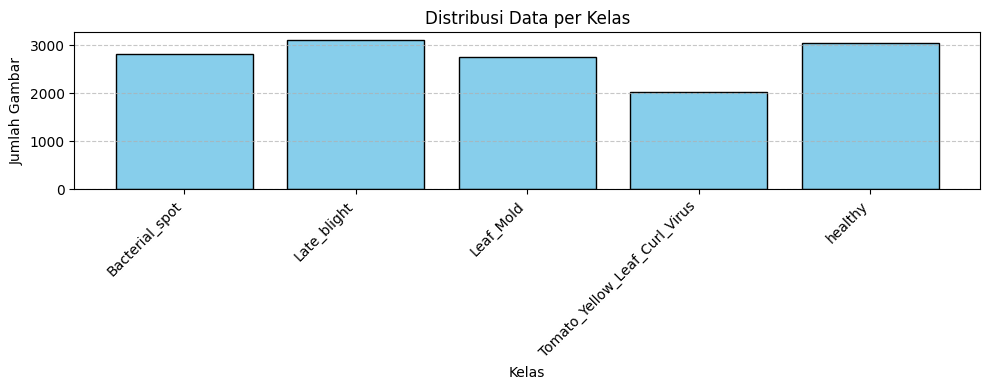

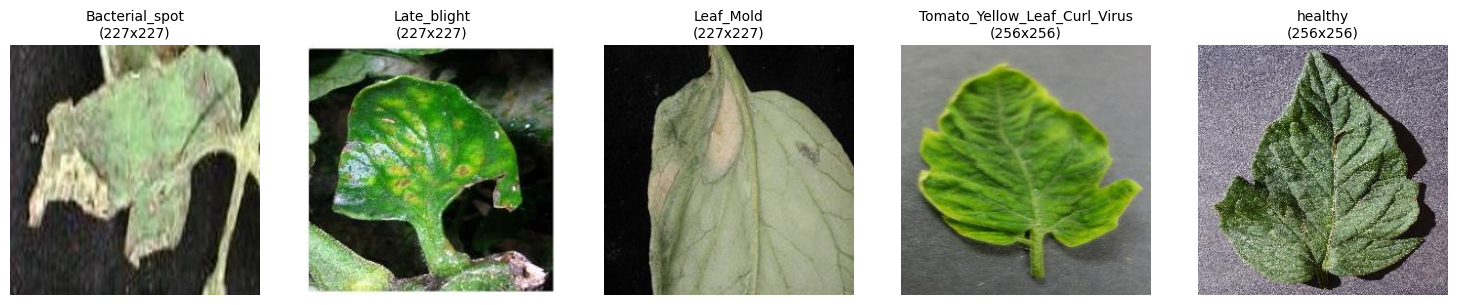

In [ ]:
import os
import glob
import matplotlib.pyplot as plt
from PIL import Image

# Path
DATASET_DIR = '/content/drive/MyDrive/dataset'

# Ekstensi gambar yang didukung
valid_extensions = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')

# Ambil daftar kelas dan hitung distribusi gambar
class_counts = {}
for class_name in sorted(os.listdir(DATASET_DIR)):
    class_path = os.path.join(DATASET_DIR, class_name)
    if os.path.isdir(class_path):
        images = [f for f in os.listdir(class_path) if f.lower().endswith(valid_extensions)]
        class_counts[class_name] = len(images)

total_images = sum(class_counts.values())
total_classes = len(class_counts)

print(f"Total Kelas  : {total_classes}")
print(f"Total Gambar : {total_images}\n")
print("Distribusi per kelas:")
for cls, count in class_counts.items():
    print(f" - {cls}: {count} gambar")

# Visualisasi Distribusi Data (Bar Chart)
plt.figure(figsize=(10, 4))
plt.bar(class_counts.keys(), class_counts.values(), color='skyblue', edgecolor='black')
plt.title('Distribusi Data per Kelas')
plt.xlabel('Kelas')
plt.ylabel('Jumlah Gambar')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Contoh Gambar dari Tiap Kelas
num_cols = min(5, total_classes)
num_rows = (total_classes + num_cols - 1) // num_cols

fig, axes = plt.subplots(num_rows, num_cols, figsize=(3 * num_cols, 3 * num_rows))
if total_classes == 1:
    axes = [axes]
else:
    axes = axes.flatten()

for idx, (cls, count) in enumerate(class_counts.items()):
    class_path = os.path.join(DATASET_DIR, cls)
    image_files = [f for f in os.listdir(class_path) if f.lower().endswith(valid_extensions)]

    ax = axes[idx]
    if image_files:
        sample_img_path = os.path.join(class_path, image_files[0])
        img = Image.open(sample_img_path)
        ax.imshow(img)
        ax.set_title(f"{cls}\n({img.size[0]}x{img.size[1]})", fontsize=10)
    else:
        ax.text(0.5, 0.5, 'Kosong', ha='center', va='center')
    ax.axis('off')

# Matikan subplot sisa jika ada slot kosong di grid
for ax in axes[idx + 1:]:
    ax.axis('off')

plt.tight_layout()
plt.show()

## Preprocessing data

In [ ]:
#Melakukan Cleaning data
import os
from PIL import Image

# os.remove(file_path)

dataset_path = '/content/drive/MyDrive/dataset'
corrupted_files = []

print("Memulai proses cleaning data...")

# Menelusuri setiap folder kelas di dalam dataset
for folder_name in os.listdir(dataset_path):
    folder_path = os.path.join(dataset_path, folder_name)

    # Pastikan yang dibaca adalah folder (bukan file nyasar)
    if os.path.isdir(folder_path):
        for file_name in os.listdir(folder_path):
            file_path = os.path.join(folder_path, file_name)

            try:
                # Mencoba membuka gambar dan memverifikasi integritasnya
                img = Image.open(file_path)
                img.verify()
            except (IOError, SyntaxError) as e:
                print(f"Gambar rusak ditemukan: {file_path}")
                corrupted_files.append(file_path)

                # Menghapus file yang rusak (hapus tanda '#' di bawah ini jika ingin otomatis dihapus)
                os.remove(file_path)

if len(corrupted_files) == 0:
    print("Cleaning selesai! Tidak ada gambar yang rusak. Dataset Anda aman.")
else:
    print(f"Cleaning selesai! Total {len(corrupted_files)} gambar rusak telah dihapus.")

In [ ]:
import tensorflow as tf

dataset_path = '/content/drive/MyDrive/dataset'
batch_size = 32
img_size = (244, 244)

# Memuat dataset gambar dari direktori
train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,#20% untuk validasi
    subset="training",
    seed=123, #Digunakan untuk pemisah antar data agar konsisten
    image_size=img_size,
    batch_size=batch_size
)

# Memuat data Validasi
val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_path,
    validation_split=0.2,
    subset="validation",
    seed = 123,
    image_size=img_size,
    batch_size=batch_size
)

#Layer Normalisasi (mengubah piksel dari 1-255 menjadi 0-1)
normalization_layer = tf.keras.layers.Rescaling(1./255)

#Menambahkan layer normalisasi ke dataset
train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds = val_ds.map(lambda x, y: (normalization_layer(x), y))

#optimasi peforma
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

print("Preprocessing Selesai. Dataset Siap dilatih!")